# Employee Sentiment & Engagement Analysis

**Goal.** Starting from an *unlabelled* file of employee e-mails (`data/test.csv`) we
1. label every message Positive / Negative / Neutral,
2. explore the data (EDA),
3. compute a monthly sentiment score per employee,
4. rank employees (top-3 positive / top-3 negative),
5. flag *flight risks* (>= 4 negative e-mails inside any rolling 30-day window), and
6. fit a linear-regression model of sentiment trends.

**How to read this notebook.** Every section has a title, a short statement of method,
the code, and an **Observations** note written after looking at the output.
Reusable logic lives in `src/` (`preprocessing.py`, `sentiment.py`, `analysis.py`) and is
unit-tested in `tests/`; this notebook is the narrative that ties it together.

| Section | Task |
|---|---|
| 0 | Setup & data loading |
| 1 | Sentiment labelling |
| 2 | Exploratory data analysis |
| 3 | Monthly employee scores |
| 4 | Employee ranking |
| 5 | Flight-risk identification |
| 6 | Predictive modelling (linear regression) |
| 7 | Summary & exports |

## 0. Setup & data loading

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("MPLBACKEND") is None and not hasattr(sys, "ps1") and "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

# make `src` importable whether the notebook is run from notebooks/ or the project root
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from src.preprocessing import load_raw, prepare
from src.sentiment import (label_dataframe, label_from_score, explain_text,
                           POS_THRESHOLD, NEG_THRESHOLD)
from src.analysis import (add_message_score, monthly_scores, rank_monthly, overall_ranking,
                          flight_risk_windows, flight_risk_summary, flight_risk_bruteforce,
                          build_model_table, fit_linear_model)

DATA = os.environ.get("DATA_PATH") or os.path.join(ROOT, "data", "test.csv")   # optional override, see .env.example
VIZ = os.path.join(ROOT, "visualization"); OUT = os.path.join(ROOT, "outputs")
os.makedirs(VIZ, exist_ok=True); os.makedirs(OUT, exist_ok=True)

# ---- plotting style: one consistent, colour-blind-safe set (blue / grey / orange) ----
C = {"Positive": "#2a78d6", "Neutral": "#a8a79f", "Negative": "#eb6834",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3de", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["grid"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "text.color": C["ink"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})
def save(fig, name):
    fig.savefig(os.path.join(VIZ, name), dpi=150, bbox_inches="tight"); plt.show()
def short(e): return e.split("@")[0].replace(".", " ").title()
ORDER = ["Positive", "Neutral", "Negative"]

In [2]:
raw = load_raw(DATA)
print("Raw file shape:", raw.shape)
print("Columns:", list(raw.columns))
raw.head(3)

Raw file shape: (2191, 4)
Columns: ['Subject', 'body', 'date', 'from']


,Subject,body,date,from
0,EnronOptions Update!,"EnronOptions Announcement\n\n\nWe have updated the EnronOptions =01) Your Stock Option Program web site! =\nThe=20\nweb site now contains specific details of the EnronOptions Program includin=\ng=20\nthe December 29, 2000 grant price and additional information on employee=20\neligibility.\n\nAccess EnronOptions =01) Your Stock Option Program web site by clicking on=\n=20\nhttp://hrweb.enron.com or by typing the address into your web browser.\n\nWe hope you find the revised site helpful in addressing your questions abou=\nt=20\nthe EnronOptions Program. If you have any additional questions, please=20\ncontact your H.R. Representative.\n\nStay tuned for more information throughout March and April 2001.",5/10/2010,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to work for the revenue model for mid & \nback office services meeting. How about this coming Monday, Feb 26 from 1:00 \n- 2:30 pm? I have penciled in that time for Sally, Mary Solmonson & James \nScribner. Please let me know if that will work for you.\n\nThanks,\nPatti x39106",7/29/2010,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 AM (GMT-06:00) Central Time (US & Canada).\nWhere: @ 10:00am CST (225) 931-8111\n\n*~*~*~*~*~*~*~*~*~*\n\n",7/25/2011,sally.beck@enron.com


**Observations.** `test.csv` is really *tab-separated* (despite the extension) and message
bodies contain quoted line-breaks, so the loader auto-detects the delimiter and uses a quote
character. Four columns: `Subject`, `body`, `date` (month/day/year), `from` (the sender - the
"employee"). Bodies also contain mail-transport artefacts (`=20`, `=\n` quoted-printable codes)
and quoted earlier messages, which would pollute sentiment scoring - the cleaning step below removes them.

In [3]:
df = prepare(raw)          # parse dates, clean subject/body, build the text that will be scored
df[["employee", "date", "month", "subject_clean", "body_clean"]].head(5)

,employee,date,month,subject_clean,body_clean
0,sally.beck@enron.com,2010-05-10,2010-05,EnronOptions Update!,"EnronOptions Announcement We have updated the EnronOptions ) Your Stock Option Program web site! The web site now contains specific details of the EnronOptions Program including the December 29, 2000 grant price and additional information on employee eligibility. Access EnronOptions ) Your Stock Option Program web site by clicking on or by typing the address into your web browser. We hope you find the revised site helpful in addressing your questions about the EnronOptions Program. If you have any additional questions, please contact your H.R. Representative. Stay tuned for more information throughout March and April 2001."
1,eric.bass@enron.com,2010-07-29,2010-07,,"Marc, Unfortunately, today is not going to work for the revenue model for mid & back office services meeting. How about this coming Monday, Feb 26 from 1:00 - 2:30 pm? I have penciled in that time for Sally, Mary Solmonson & James Scribner. Please let me know if that will work for you. Thanks, Patti x39106"
2,sally.beck@enron.com,2011-07-25,2011-07,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 AM (GMT-06:00) Central Time (US & Canada). Where: @ 10:00am CST (225) 931-8111 *~*~*~*~*~*~*~*~*~*"
3,johnny.palmer@enron.com,2010-03-25,2010-03,My new work email,we were thinking papasitos (we can meet somewhere closer to you this time) again at around 8 Jason Bass on 02/21/2001 11:22:45 AM
4,lydia.delgado@enron.com,2011-05-21,2011-05,Bet,"Since you never gave me the $20 for the last time we bet on CU/Texas, I figured I would give you the chance to go double or nothing on the second round. I think the line is Texas -9. Let me know."


## 1. Sentiment labelling (Task 1)

**Method - a transparent, reproducible lexicon scorer** (`src/sentiment.py`).

* *Why not an LLM?* The brief prefers an LLM "or any suitable NLP technique". This project was
  built in an offline environment with no pretrained models, so it uses a VADER-style
  lexicon approach written from scratch. It is deterministic (same input -> same label), free
  to run, and every decision can be inspected. No LLM was used; see the limitations in
  Section 7 and the README for how an LLM could be swapped in and used to validate these labels.
* *Cleaning first.* Quoted-printable codes, URLs, e-mail addresses, quoted/forwarded history
  (`-----Original Message-----`, `>` lines) are removed so that only the sender's own words
  are scored. The subject is prepended to the body.
* *Scoring.* Each word has a valence (-4..+4). Negations ("not good") flip & dampen, boosters
  ("very") amplify. Valences are summed and squashed: `compound = s / sqrt(s^2 + 15)` in [-1, 1].
* *Labels.* `compound >= +0.25` -> **Positive**, `<= -0.25` -> **Negative**, otherwise **Neutral**.
  The band is wider than VADER's default (+-0.05) because business e-mail is full of politeness
  ("thanks", "please") that should not make a scheduling note "Positive".
* *Domain adjustments (found by error analysis).* After reading the messages behind the first
  flight-risk results, three artefacts were fixed: legal confidentiality footers (which contain the word
  "error") and closing salutations ("Best regards" -> the positive word "best") are stripped in
  `preprocessing.py`, and "risk" / "outage" (department names and routine IT notices in this corpus) carry no
  sentiment. These changes were made *after* seeing the first results, so the final labels are tuned by
  inspection, not blind - another reason to treat the flags as indicative.

In [4]:
df = label_dataframe(df)    # adds sentiment_score (compound) and sentiment (label)
counts = df["sentiment"].value_counts().reindex(ORDER)
pd.DataFrame({"messages": counts, "share_%": (counts / len(df) * 100).round(1)})

,messages,share_%
sentiment,,
Positive,646,29.5
Neutral,1382,63.1
Negative,163,7.4


In [5]:
# Spot-check: 4 random messages per label, with the lexicon words that drove each decision
pd.set_option("display.max_colwidth", 140, "display.width", 200)
rows = []
for lab in ORDER:
    for _, r in df[(df.sentiment == lab) & (df.text.str.len() > 0)].sample(4, random_state=11).iterrows():
        rows.append({"label": lab, "score": round(r.sentiment_score, 2),
                     "text": r.text[:130], "drivers": ", ".join(f"{w}({v:+.1f})" for w, v in explain_text(r.text)[:5])})
pd.DataFrame(rows)

,label,score,text,drivers
0,Positive,0.44,\\GTROS-FS01P\APPSRW. This is a message from Kerry. I just converted and moved Larry Campbell (lcampbe) to the W2K server. He uses,"successfully(+2.3), cannot(-0.8), thanks(+0.4)"
1,Positive,0.70,Sally's itinerary 1/2/01. We will also have both of our cell phones with us: David 713-299-1436 Sally 713-417-1591 We will hope fo,"hope(+0.6), love(+2.8)"
2,Positive,0.30,Per my voice mail. 1) Y2K Team: Let me know if you would like to send a notes mail message from you to the individuals that were h,"like(+0.2), welcome(+1.0)"
3,Positive,0.73,"hey dad. thanks for the invite but I won't be able to get away for lunch. we had a great trip this weekend, its good to live the s","thanks(+0.4), won't(-0.7), great(+2.5), good(+1.9)"
4,Neutral,0.10,"Phone Interview Confirmation - Monday, April 30, 2001 - Steven\n Coulter. Steven Coulter is confirmed for a telephone interview on",thank(+0.4)
5,Neutral,0.00,"Into Cinergy Hourly Index for November 20, 2001. <<CinergyHourlyTableNov20.xls>> Lisa Lawson Markets Editor Platts - Megawatt Dail",
6,Neutral,0.00,"NOTICE TO ALL. After 3 horrific weeks of being in the no-internet gulag, I am back on-line. Now you know why I haven't been answer",
7,Neutral,0.00,MAPP OASIS Partial Outage. fyi,
8,Negative,-0.46,RBs. Do you believe that your RBs suck now? Do you want some help - I am your man,"suck(-2.4), help(+0.4)"
9,Negative,-0.40,"NEW PASSWORD FOR EXELON (CE) CHECKOUTS. Hey guys, Power Team (CE) made us change the password for checkouts. The new info is as fo",problems(-1.7)


In [6]:
# Sensitivity: how much do the label shares depend on the +-threshold?
sens = {}
for t in (0.15, 0.25, 0.35):
    lab = df["sentiment_score"].map(lambda s: label_from_score(s, t, -t))
    sens[f"+-{t}"] = (lab.value_counts(normalize=True).reindex(ORDER) * 100).round(1)
pd.DataFrame(sens).rename_axis("share % at threshold")

,+-0.15,+-0.25,+-0.35
share % at threshold,,,
Positive,36.1,29.5,24.1
Neutral,54.2,63.1,71.2
Negative,9.8,7.4,4.6


**Observations.**
* Neutral dominates (about **63%**), then Positive (**30%**), and Negative is a small minority
  (**7%**, 163 messages). That is plausible for routine corporate e-mail (scheduling, forwarding,
  data requests) with occasional congratulations/pleasantries and rarer complaints.
* The spot-check shows labels driven by sensible words (e.g. *congratulations, appreciate* ->
  Positive; *sorry, wrong, problem* -> Negative). Known weaknesses: no sarcasm detection, and
  words with trade meaning ("loss matrix", "cancellation notice") can still mis-fire.
  A hand-check of 40 random messages (seed 7, reading the first ~260 characters of each) judged
  **33 of 40** labels reasonable. The 7 doubtful ones were mostly neutral-in-spirit mails given a
  Positive/Negative label on one or two words (job enquiries, an orientation notice, a
  "customer requested cancel" notice, a joke). This is a small, subjective check by the author,
  **not** a measured accuracy (there are no ground-truth labels).
* The sensitivity table shows the Negative share moves between ~5% and ~10% as the threshold goes
  from 0.35 to 0.15, so **Negative counts (and therefore flight-risk results) are threshold-dependent**.
  We keep +-0.25 as the documented, fixed choice.

## 2. Exploratory data analysis (Task 2)

### 2.1 Structure, types, missing values and data quality

In [7]:
print("Records:", len(df), "| Columns in raw file:", raw.shape[1])
print("Date range:", df.date.min().date(), "->", df.date.max().date(), "| months:", df.month.nunique())
print("Employees (senders):", df.employee.nunique())
print()
print(raw.dtypes.rename("dtype").to_frame().join(raw.isna().sum().rename("missing")))
quality = pd.Series({
    "rows with '(No Subject)'/empty subject": int((df.subject_clean == "").sum()),
    "rows whose body is empty after cleaning": int((df.body_clean == "").sum()),
    "rows with NO usable text (subject+body)": int((df.text == "").sum()),
    "rows sharing subject+body with another row": int(df.duplicated(["subject", "body"], keep=False).sum()),
    "bodies at the 999-char truncation limit": int((raw["body"].str.len() >= 990).sum()),
    "bodies mentioning 1999-2002": int(df.body.str.contains(r"\b(?:1999|2000|2001|2002)\b").sum()),
    "bodies mentioning 2010 or 2011": int(df.body.str.contains(r"\b(?:2010|2011)\b").sum()),
}, name="count")
quality

Records: 2191 | Columns in raw file: 4
Date range: 2010-01-01 -> 2011-12-31 | months: 24
Employees (senders): 10

        dtype  missing
Subject   str        0
body      str        0
date      str        0
from      str        0


rows with '(No Subject)'/empty subject         243
rows whose body is empty after cleaning         75
rows with NO usable text (subject+body)         32
rows sharing subject+body with another row    1074
bodies at the 999-char truncation limit          2
bodies mentioning 1999-2002                    576
bodies mentioning 2010 or 2011                   0
Name: count, dtype: int64

In [8]:
msgs_per_month = df.groupby("month").size()
print("Messages per month: min", msgs_per_month.min(), "| max", msgs_per_month.max())
print("Employee-months with at least one message:", df.groupby(["employee", "month"]).ngroups, "of", df.employee.nunique() * df.month.nunique())
df.groupby("employee").size().sort_values(ascending=False).rename("messages").to_frame()

Messages per month: min 91 | max 92
Employee-months with at least one message: 240 of 240


,messages
employee,
lydia.delgado@enron.com,284
john.arnold@enron.com,256
sally.beck@enron.com,227
patti.thompson@enron.com,225
bobette.riner@ipgdirect.com,217
don.baughman@enron.com,213
johnny.palmer@enron.com,213
eric.bass@enron.com,210
kayne.coulter@enron.com,174


**Observations (data quality - important).**
* No *formal* missing values, but **243 messages have no subject**, **32 have no usable text** at all
  (these are scored Neutral), and two bodies hit the 999-character export limit, i.e. bodies are
  **truncated** (sentiment late in long mails is invisible).
* **The `date` column looks synthetic.** Every month contains exactly 91-92 messages (an almost
  perfectly even spread), and **576 bodies mention 1999-2002 while none mention 2010 or 2011** - the
  original mails are from ~2000-2001 and the dates appear to have been reassigned. All "trends over
  time" below are therefore trends **over the dates in the file**, not necessarily real chronology.
* **About 49% of rows (1,074) share their subject and body with at least one other row** - mostly the
  same mail appearing under several senders (only 82 rows are same-sender repeats). We keep them
  (each is a message that employee sent) and test the effect on flight risk in section 5.
* One sender (`bobette.riner@ipgdirect.com`) is an external domain; the other nine are `@enron.com`.
  All 10 senders appear in all 24 months, so no employee-month is missing.

### 2.2 Distribution of sentiment

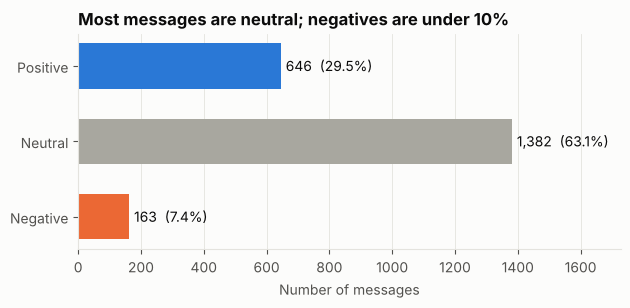

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.8))
vals = df["sentiment"].value_counts().reindex(ORDER[::-1])
bars = ax.barh(vals.index, vals.values, color=[C[k] for k in vals.index], height=0.6)
for b, v in zip(bars, vals.values):
    ax.text(v + 15, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / len(df):.1%})", va="center", color=C["ink"])
ax.set_xlim(0, vals.max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_title("Most messages are neutral; negatives are under 10%"); ax.set_xlabel("Number of messages")
save(fig, "01_sentiment_distribution.png")

**Observations.** Neutral 1,382 (63.1%), Positive 646 (29.5%), Negative 163 (7.4%). Because
negatives are rare, *four or more in a month window* (the flight-risk rule) is a high bar.

### 2.3 Trends over time

LinregressResult(slope=np.float64(0.00464571345478718), intercept=np.float64(0.16705128205128206), rvalue=np.float64(0.6291132340709736), pvalue=np.float64(0.0009902851372353737), stderr=np.float64(0.001223794683102333), intercept_stderr=np.float64(0.01642652820859748))


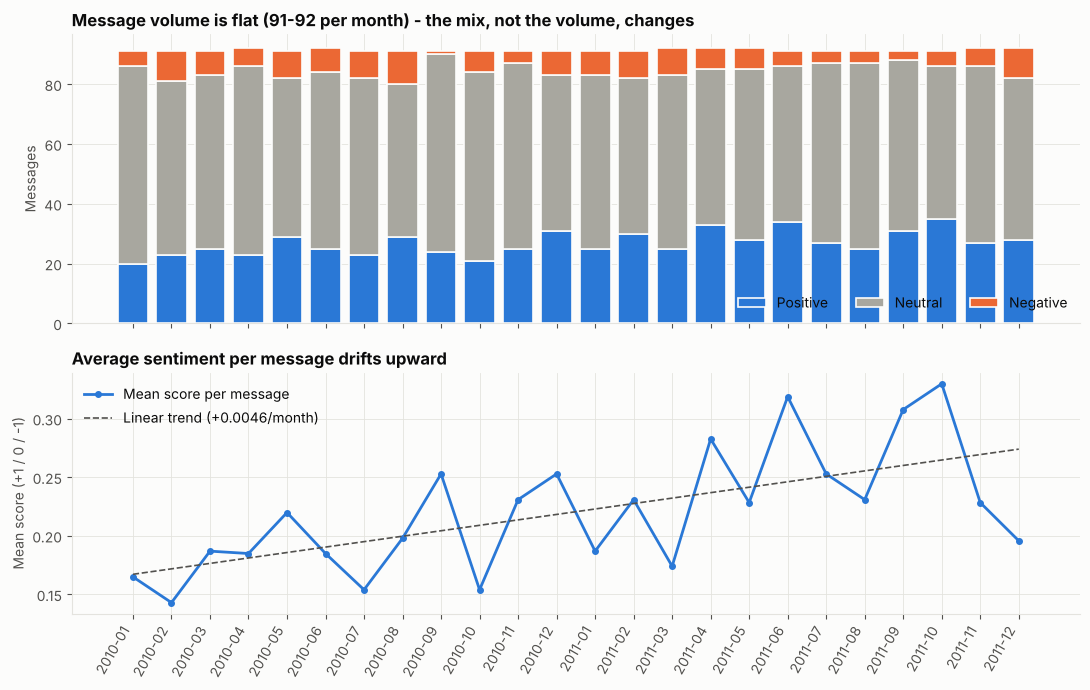

In [10]:
mon = df.groupby(["month", "sentiment"]).size().unstack(fill_value=0)[ORDER]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
bottom = np.zeros(len(mon))
for lab in ORDER:
    axes[0].bar(mon.index, mon[lab], bottom=bottom, color=C[lab], label=lab, edgecolor=C["surface"], linewidth=1.2)
    bottom += mon[lab].values
axes[0].set_title("Message volume is flat (91-92 per month) - the mix, not the volume, changes")
axes[0].set_ylabel("Messages"); axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.02)) if False else axes[0].legend(ncol=3, loc="lower right")
net = df["sentiment"].map({"Positive": 1, "Neutral": 0, "Negative": -1}).groupby(df["month"]).mean()
x = np.arange(len(net)); slope, icpt = np.polyfit(x, net.values, 1)
axes[1].plot(net.index, net.values, color=C["Positive"], lw=2, marker="o", ms=4, label="Mean score per message")
axes[1].plot(net.index, icpt + slope * x, color=C["ink2"], lw=1.2, ls="--", label=f"Linear trend ({slope:+.4f}/month)")
axes[1].set_title("Average sentiment per message drifts upward"); axes[1].set_ylabel("Mean score (+1 / 0 / -1)")
axes[1].legend(loc="upper left")
plt.setp(axes[1].get_xticklabels(), rotation=60, ha="right"); fig.tight_layout()
save(fig, "02_monthly_volume_and_trend.png")
from scipy import stats
print(stats.linregress(x, net.values))

**Observations.** Volume is essentially constant (see data-quality note), so changes come from the
*mix*. The mean score per message is ~0.14-0.19 in the first months of 2010 and ~0.2-0.33 in the last
months of 2011; the fitted slope is about **+0.0046 per month** (r = 0.63, p = 0.001) - a statistically
visible but modest drift towards more positive wording. Monthly values still bounce around (0.14 to 0.33), so no single month
should be over-interpreted.

### 2.4 Sentiment by employee

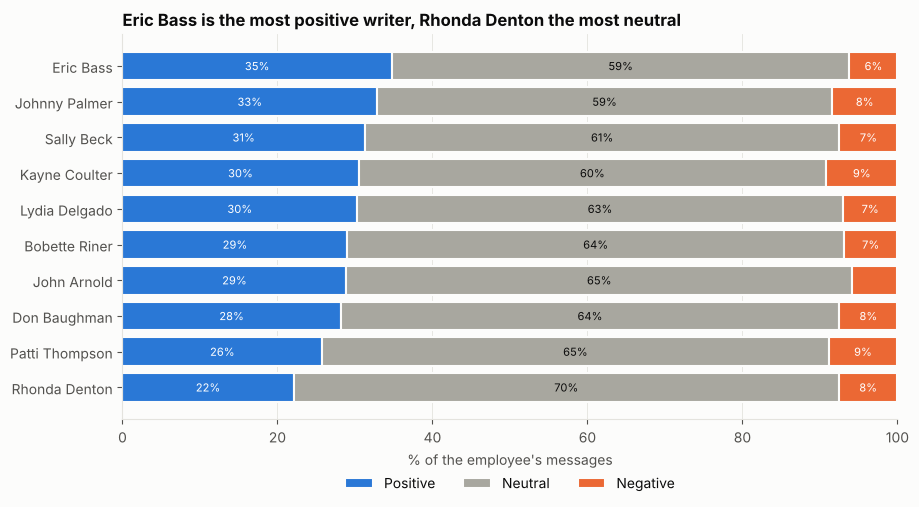

sentiment,Positive,Neutral,Negative
employee,,,
rhonda.denton@enron.com,22.1,70.3,7.6
patti.thompson@enron.com,25.8,65.3,8.9
don.baughman@enron.com,28.2,64.3,7.5
john.arnold@enron.com,28.9,65.2,5.9
bobette.riner@ipgdirect.com,29.0,64.1,6.9
lydia.delgado@enron.com,30.3,62.7,7.0
kayne.coulter@enron.com,30.5,60.3,9.2
sally.beck@enron.com,31.3,61.2,7.5
johnny.palmer@enron.com,32.9,58.7,8.5


In [11]:
share = pd.crosstab(df["employee"], df["sentiment"], normalize="index")[ORDER] * 100
share = share.sort_values("Positive")
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(share))
for lab in ORDER:
    ax.barh([short(e) for e in share.index], share[lab], left=left, color=C[lab], label=lab, edgecolor=C["surface"], linewidth=1.5)
    for y, (l, v) in enumerate(zip(left, share[lab])):
        if v > 6: ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white" if lab != "Neutral" else C["ink"], fontsize=8)
    left += share[lab].values
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xlabel("% of the employee's messages")
ax.set_title("Eric Bass is the most positive writer, Rhonda Denton the most neutral"); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.22))
save(fig, "03_sentiment_by_employee.png")
share.round(1)

**Observations.** Differences between people are modest: positive share ranges from ~22% (Rhonda
Denton) to ~35% (Eric Bass) and negative share from ~6% (John Arnold) to ~9% (Kayne Coulter).
Rhonda Denton and Patti Thompson have the lowest positive shares (22% and 26%) and also write mostly
neutral mail (70% and 65%).

### 2.5 Other patterns: message length, and employee x month intensity

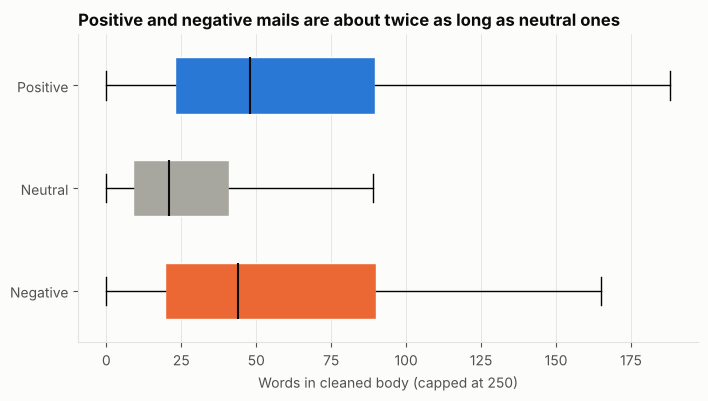

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Positive,646.0,59.0,41.9,0.0,23.0,48.0,89.8,188.0
Neutral,1382.0,30.5,31.2,0.0,9.0,21.0,41.0,173.0
Negative,163.0,59.1,44.2,0.0,19.5,44.0,90.0,165.0


In [12]:
df["word_count"] = df["body_clean"].str.split().str.len().fillna(0)
fig, ax = plt.subplots(figsize=(8, 4))
data = [df.loc[df.sentiment == l, "word_count"].clip(upper=250) for l in ORDER]
bp = ax.boxplot(data, vert=False, tick_labels=ORDER, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=C["ink"], lw=1.5))
for patch, l in zip(bp["boxes"], ORDER): patch.set_facecolor(C[l]); patch.set_edgecolor(C["surface"])
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("Words in cleaned body (capped at 250)")
ax.set_title("Positive and negative mails are about twice as long as neutral ones")
save(fig, "04_length_by_sentiment.png")
df.groupby("sentiment")["word_count"].describe().round(1).loc[ORDER]

**Observations.** Median length is ~21 words for Neutral versus ~44-48 for Positive/Negative. Part of
this is mechanical: a bag-of-words scorer has more chances to hit a sentiment word in a longer text.
Short logistics mails ("see attached", "game at 7") are almost always Neutral.

## 3. Employee score calculation (Task 3)

**Method.** Each message gets a score: **Positive = +1, Negative = -1, Neutral = 0**. Scores are
summed per *employee x calendar month* (`groupby(["month", "employee"])`). The score "resets" every
month automatically, because a message only ever belongs to the month in which it was sent - there is
no running total carried over. An employee who sent nothing in a month has no row; in this dataset
that never happens (all 240 employee-months exist).

In [13]:
df = add_message_score(df)
scores = monthly_scores(df)
print(scores.shape, "->", scores.employee.nunique(), "employees x", scores.month.nunique(), "months")

# --- validation 1: totals must reconcile with the message-level scores
assert scores["monthly_score"].sum() == df["message_score"].sum()
assert scores["n_messages"].sum() == len(df)
assert (scores["n_positive"] - scores["n_negative"] == scores["monthly_score"]).all()
# --- validation 2: re-compute one employee-month by hand
chk = df[(df.employee == "sally.beck@enron.com") & (df.month == "2010-05")]
print("Sally Beck 2010-05 by hand:", chk["message_score"].sum(), "| table:",
      scores.query("employee=='sally.beck@enron.com' and month=='2010-05'")["monthly_score"].iloc[0])
scores.head(10)

(240, 7) -> 10 employees x 24 months
Sally Beck 2010-05 by hand: 3 | table: 3


,month,employee,monthly_score,n_messages,n_positive,n_negative,n_neutral
0,2010-01,bobette.riner@ipgdirect.com,0,2,0,0,2
1,2010-01,don.baughman@enron.com,2,9,3,1,5
2,2010-01,eric.bass@enron.com,4,10,4,0,6
3,2010-01,john.arnold@enron.com,0,7,1,1,5
4,2010-01,johnny.palmer@enron.com,1,6,1,0,5
5,2010-01,kayne.coulter@enron.com,3,22,4,1,17
6,2010-01,lydia.delgado@enron.com,2,13,3,1,9
7,2010-01,patti.thompson@enron.com,1,10,1,0,9
8,2010-01,rhonda.denton@enron.com,1,3,1,0,2
9,2010-01,sally.beck@enron.com,1,9,2,1,6


Employee-months with a negative score: 10 of 240
Score range: -1 to 8


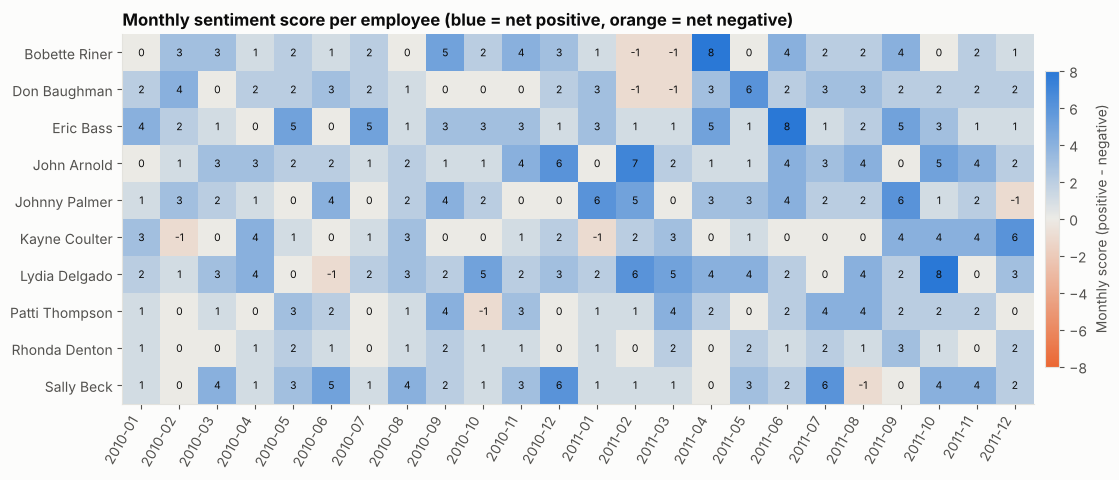

In [14]:
pivot = scores.pivot(index="employee", columns="month", values="monthly_score")
pivot.index = [short(e) for e in pivot.index]
cmap = LinearSegmentedColormap.from_list("div", [C["Negative"], "#ecebe6", C["Positive"]])
lim = np.abs(pivot.values).max()
fig, ax = plt.subplots(figsize=(14, 4.8))
im = ax.imshow(pivot.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns, rotation=60, ha="right")
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index); ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, int(pivot.values[i, j]), ha="center", va="center", fontsize=7.5, color=C["ink"])
cb = fig.colorbar(im, ax=ax, pad=0.01, shrink=0.8); cb.set_label("Monthly score (positive - negative)")
ax.set_title("Monthly sentiment score per employee (blue = net positive, orange = net negative)")
save(fig, "05_employee_month_heatmap.png")
print("Employee-months with a negative score:", int((scores.monthly_score < 0).sum()), "of", len(scores))
print("Score range:", scores.monthly_score.min(), "to", scores.monthly_score.max())

**Observations.** Scores are small integers because most messages are neutral. Net-negative
employee-months are rare (see count above) and most cells are mildly positive, mirroring the overall
mix. The maximum monthly score is driven as much by *how many* messages someone sent as by tone - this
matters for the regression in section 6.

## 4. Employee ranking (Task 4)

**Method.** Using the monthly scores from section 3, for each month:
* **Top-3 positive** - the three highest scores, sorted by score *descending*, ties broken
  *alphabetically* by employee.
* **Top-3 negative** - the three *lowest* scores, most negative first, ties broken alphabetically.

Because every month has ten employees and scores are small integers, ties are common; the
alphabetical rule makes the output deterministic, but it means a tie at the cut-off is decided by
name, not by evidence. We also give a whole-period ranking (sum of the 24 monthly scores) for the
headline "top 3".

In [15]:
top_pos, top_neg = rank_monthly(scores, top_n=3)
for d in (top_pos, top_neg): d["name"] = d["employee"].map(short)
print("Example - 2010-01 and 2011-12")
display_cols = ["month", "rank", "name", "monthly_score"]
pd.concat([top_pos[top_pos.month.isin(["2010-01", "2011-12"])][display_cols].assign(list="Top positive"),
           top_neg[top_neg.month.isin(["2010-01", "2011-12"])][display_cols].assign(list="Top negative")])

Example - 2010-01 and 2011-12


,month,rank,name,monthly_score,list
0,2010-01,1,Eric Bass,4,Top positive
1,2010-01,2,Kayne Coulter,3,Top positive
2,2010-01,3,Don Baughman,2,Top positive
69,2011-12,1,Kayne Coulter,6,Top positive
70,2011-12,2,Lydia Delgado,3,Top positive
71,2011-12,3,Don Baughman,2,Top positive
0,2010-01,1,Bobette Riner,0,Top negative
1,2010-01,2,John Arnold,0,Top negative
2,2010-01,3,Johnny Palmer,1,Top negative
69,2011-12,1,Johnny Palmer,-1,Top negative


In [16]:
overall = overall_ranking(scores)
overall["score_per_message"] = (overall["total_score"] / overall["n_messages"]).round(3)
overall["name"] = overall["employee"].map(short)
overall[["name", "employee", "total_score", "n_messages", "score_per_message", "n_positive", "n_negative"]]

,name,employee,total_score,n_messages,score_per_message,n_positive,n_negative
0,Lydia Delgado,lydia.delgado@enron.com,66,284,0.232,86,20
1,Eric Bass,eric.bass@enron.com,60,210,0.286,73,13
2,John Arnold,john.arnold@enron.com,59,256,0.230,74,15
3,Sally Beck,sally.beck@enron.com,54,227,0.238,71,17
4,Johnny Palmer,johnny.palmer@enron.com,52,213,0.244,70,18
5,Bobette Riner,bobette.riner@ipgdirect.com,48,217,0.221,63,15
6,Don Baughman,don.baughman@enron.com,44,213,0.207,60,16
7,Patti Thompson,patti.thompson@enron.com,38,225,0.169,58,20
8,Kayne Coulter,kayne.coulter@enron.com,37,174,0.213,53,16
9,Rhonda Denton,rhonda.denton@enron.com,25,172,0.145,38,13


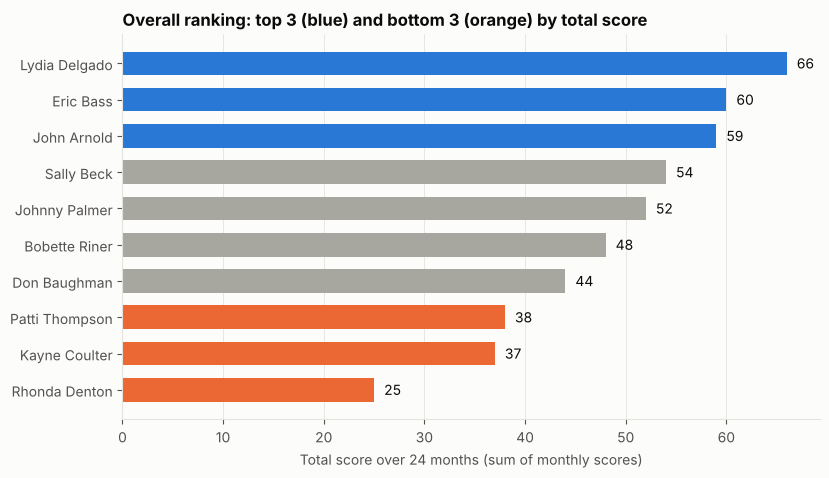

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
o = overall.sort_values("total_score")
colors = [C["Positive"] if i >= len(o) - 3 else (C["Negative"] if i < 3 else C["Neutral"]) for i in range(len(o))]
bars = ax.barh(o["name"], o["total_score"], color=colors, height=0.65)
for b, v in zip(bars, o["total_score"]): ax.text(v + 1, b.get_y() + b.get_height() / 2, str(v), va="center")
ax.grid(axis="y", visible=False); ax.set_xlabel("Total score over 24 months (sum of monthly scores)")
ax.set_title("Overall ranking: top 3 (blue) and bottom 3 (orange) by total score")
save(fig, "06_overall_ranking.png")

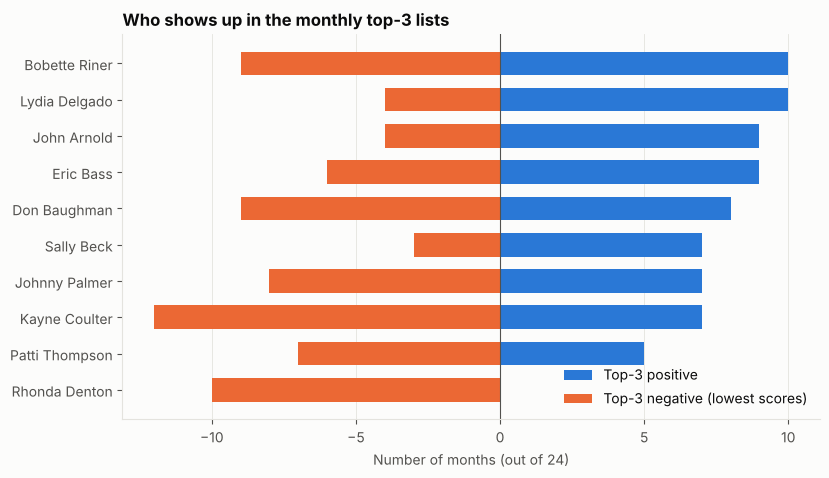

,months in top-3 positive,months in top-3 negative
Bobette Riner,10,9
Lydia Delgado,10,4
Eric Bass,9,6
John Arnold,9,4
Don Baughman,8,9
Sally Beck,7,3
Kayne Coulter,7,12
Johnny Palmer,7,8
Patti Thompson,5,7
Rhonda Denton,0,10


In [18]:
# How often does each employee appear in a monthly top-3 / bottom-3?
app = pd.DataFrame({"months in top-3 positive": top_pos.groupby("employee").size(),
                    "months in top-3 negative": top_neg.groupby("employee").size()}).fillna(0).astype(int)
app.index = [short(e) for e in app.index]; app = app.sort_values("months in top-3 positive")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(app.index, app["months in top-3 positive"], color=C["Positive"], height=0.65, label="Top-3 positive")
ax.barh(app.index, -app["months in top-3 negative"], color=C["Negative"], height=0.65, label="Top-3 negative (lowest scores)")
ax.axvline(0, color=C["ink2"], lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of months (out of 24)"); ax.legend(loc="lower right")
ax.set_title("Who shows up in the monthly top-3 lists")
save(fig, "07_monthly_top3_appearances.png")
app.sort_values("months in top-3 positive", ascending=False)

**Observations.**
* **Top three positive (whole period):** Lydia Delgado (66), Eric Bass (60), John Arnold (59).
* **Three lowest:** Rhonda Denton (25), Kayne Coulter (37), Patti Thompson (38).
* **Careful reading:** *all ten totals are positive*, so "lowest" means *least positive*, not
  "unhappy". Totals also scale with message count (Lydia sent the most, Rhonda the fewest). Per message,
  Eric Bass is the most positive (0.286) and Rhonda Denton (0.145) and Patti Thompson (0.169) are the least -
  the per-message column is the fairer measure of tone; the total is the measure the brief asks for.
* Monthly lists change a lot from month to month (tiny integer scores, many ties), so a monthly
  top-3 is a noisy signal; the whole-period view and the appearance counts are more stable.

## 5. Flight-risk identification (Task 5)

**Definition (from the brief).** A *flight risk* is any employee who sent **4 or more negative
e-mails within 30 days**, irrespective of score and irrespective of month boundaries.

**Method.** For each employee we take their Negative messages and slide a **rolling 30-day window**
(`pandas rolling("30D")`, i.e. the day itself plus the previous 29 days). Whenever the count reaches 4
the employee is flagged and the trigger date is recorded. Choices worth knowing:
* Messages on the same day all count (4 negatives on one day is enough).
* "30 days" means 30 calendar days inclusive: negatives on 1 Jan and 30 Jan are in one window, 1 Jan
  and 31 Jan are not.
* **Robustness:** the result is cross-checked against an independent brute-force implementation, and
  boundary / month-crossing cases are unit-tested in `tests/test_pipeline.py`.

In [19]:
triggers = flight_risk_windows(df)
risk = flight_risk_summary(df)
risk["name"] = risk["employee"].map(short)

# robustness 1: independent brute-force implementation must flag exactly the same people
assert set(risk.employee) == flight_risk_bruteforce(df), "implementations disagree!"
print("Flagged (rolling-window method) == flagged (brute force):", sorted(risk.employee))
risk[["name", "employee", "first_flagged", "last_flagged", "max_negatives_in_30d", "trigger_days", "months_affected"]]

Flagged (rolling-window method) == flagged (brute force): ['bobette.riner@ipgdirect.com']


,name,employee,first_flagged,last_flagged,max_negatives_in_30d,trigger_days,months_affected
0,Bobette Riner,bobette.riner@ipgdirect.com,2011-01-28,2011-02-17,4,2,"2011-01, 2011-02"


In [20]:
# show the actual negative e-mails inside each employee's FIRST trigger window (evidence for the flag)
neg = df[df.sentiment == "Negative"]
for _, r in risk.iterrows():
    first = triggers[triggers.employee == r.employee].sort_values("trigger_date").iloc[0]
    w = neg[(neg.employee == r.employee) & (neg.date >= first.window_start) & (neg.date <= first.trigger_date)]
    print(f"\n{r['name']}: {len(w)} negative mails between {first.window_start.date()} and {first.trigger_date.date()}")
    for _, m in w.iterrows(): print(f"   {m.date.date()}  [{m.sentiment_score:+.2f}]  {m.text[:95]}")


Bobette Riner: 4 negative mails between 2010-12-30 and 2011-01-28
   2011-01-23  [-0.35]  Jacques, I think we reached an agreement with George and Larry to pick up the items of value an
   2011-01-06  [-0.56]  AEP-HPL Transition Issues. FYI - See attachment for latest attempt at satisfying the "ill-defin
   2011-01-28  [-0.53]  Harrison. your running backs suck - what do you want for harrison? rb and wr (carter)
   2011-01-25  [-0.59]  Enron Japan Weekly update.. Hello EJOT- I regret to inform you that this week's conference call


In [21]:
# robustness 2: do duplicated mails (same sender, same subject+body) drive the flags?
dedup = df.drop_duplicates(["employee", "subject", "body"])
risk_dedup = flight_risk_summary(dedup)
print(f"Rows: {len(df)} -> {len(dedup)} after dropping same-sender duplicates")
print("Flagged without duplicates:", sorted(risk_dedup.employee))
print("Flagged only WITH duplicates:", sorted(set(risk.employee) - set(risk_dedup.employee)))

# robustness 3: sensitivity to the negative threshold
for t in (0.15, 0.25, 0.35):
    tmp = df.copy(); tmp["sentiment"] = tmp["sentiment_score"].map(lambda s: label_from_score(s, t, -t))
    print(f"threshold +-{t}: flagged = {sorted(short(e) for e in flight_risk_summary(tmp).employee)}")

Rows: 2191 -> 2109 after dropping same-sender duplicates
Flagged without duplicates: ['bobette.riner@ipgdirect.com']
Flagged only WITH duplicates: []
threshold +-0.15: flagged = ['Bobette Riner', 'Don Baughman', 'Eric Bass', 'John Arnold', 'Johnny Palmer', 'Lydia Delgado', 'Patti Thompson']
threshold +-0.25: flagged = ['Bobette Riner']
threshold +-0.35: flagged = []


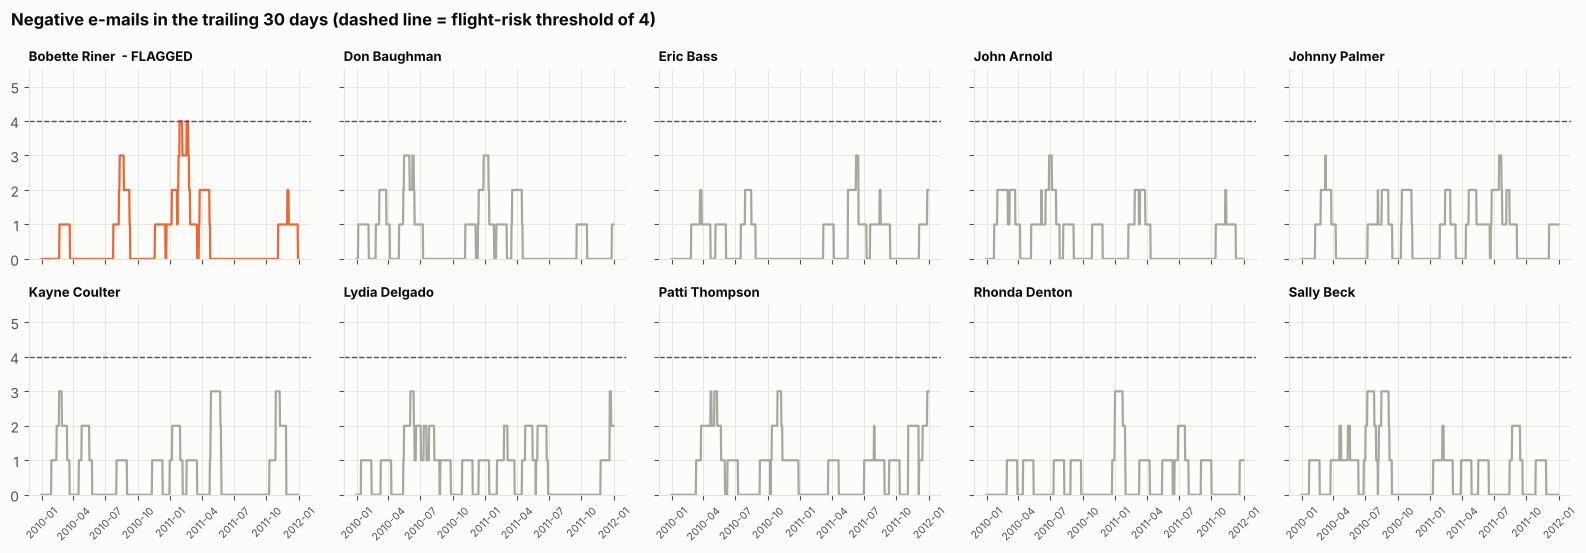

In [22]:
# visual: rolling 30-day negative count per employee, threshold = 4
days = pd.date_range(df.date.min(), df.date.max())
emps = sorted(df.employee.unique())
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6), sharex=True, sharey=True)
for ax, e in zip(axes.ravel(), emps):
    d = df[(df.employee == e) & (df.sentiment == "Negative")].groupby("date").size().reindex(days, fill_value=0)
    roll = d.rolling("30D").sum()
    flagged = e in set(risk.employee)
    ax.plot(roll.index, roll.values, color=C["Negative"] if flagged else C["Neutral"], lw=1.6)
    ax.axhline(4, color=C["ink2"], ls="--", lw=1)
    ax.fill_between(roll.index, 4, roll.values, where=roll.values >= 4, color=C["Negative"], alpha=0.35)
    ax.set_title(short(e) + ("  - FLAGGED" if flagged else ""), fontsize=9.5, color=C["ink"])
    ax.tick_params(axis="x", rotation=45, labelsize=7.5)
axes[0, 0].set_ylim(0, 5.5); fig.suptitle("Negative e-mails in the trailing 30 days (dashed line = flight-risk threshold of 4)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "08_flight_risk_timeline.png")

**Observations.**
* **One employee is flagged: Bobette Riner** - 4 negative e-mails between 30 Dec 2010 and 28 Jan 2011
  (the rule triggers again on 17 Feb 2011 as the window slides). She reached **exactly 4**, never more, so the
  flag is *marginal*: one fewer negative label and she would not be flagged.
* The four messages behind the flag are mixed: a "Transition Issues" note and an "I regret to inform you
  ... call has been canceled" notice are mildly negative business mails; one is fantasy-football banter
  ("your running backs suck"); one is a long deal e-mail with a few cautionary words. Read them before
  drawing any conclusion about the person.
* The rolling-window method and the brute-force check agree, and the window evidence list shows
  the actual messages behind each flag so a human can judge them.
* **The list is fragile.** Removing same-sender duplicates changes nothing, but the label threshold
  matters a lot: at +-0.15 **seven** employees are flagged, at +-0.25 (our setting) **one**, at +-0.35
  **none**. An earlier version of the lexicon (before the boilerplate and "risk"/"outage" fixes described in
  Section 1) flagged four people. So this is a **"worth a conversation"** signal, not proof that someone
  is about to leave - the underlying "negative" label is lexicon-based.
* A short negative burst is independent of the total score, which is why the brief defines the flag
  separately from the ranking.

## 6. Predictive modelling - linear regression (Task 6)

**Goal.** Explore whether simple, *non-sentiment* characteristics of how people write predict their
monthly sentiment score.

**Data.** One row per employee-month (240 rows). **Features** (deliberately not the sentiment words
themselves, to avoid leaking the label): `n_messages` (message frequency), `avg_word_count`,
`avg_char_length`, `avg_subject_words`, `share_questions` (share of mails containing "?"),
`share_exclaims` (share containing "!"), `month_index` (0..23, a time trend).

**Two targets.**
* **A. `monthly_score`** - the Task-3 score. Because it is a *sum*, it mechanically grows with the
  number of messages, so we expect `n_messages` to dominate.
* **B. `mean_sentiment`** - score divided by message count, i.e. tone *independent of volume*.

**Evaluation.** 80/20 random train/test split (seed 42), metrics on the held-out 20%
(R-squared, RMSE, MAE) compared with a "predict the training mean" baseline, plus 5-fold
cross-validation on the training set. Coefficient p-values come from the usual OLS t-tests (training data).

In [23]:
table = build_model_table(df, scores)
FEATURES = ["n_messages", "avg_word_count", "avg_char_length", "avg_subject_words",
            "share_questions", "share_exclaims", "month_index"]
print(table.shape); table[FEATURES + ["monthly_score", "mean_sentiment"]].describe().round(2).T

(240, 14)


,count,mean,std,min,25%,50%,75%,max
n_messages,240.0,9.13,5.73,1.0,4.75,9.00,12.00,27.0
avg_word_count,240.0,40.49,17.14,0.0,30.45,39.32,48.48,126.0
avg_char_length,240.0,233.77,97.30,0.0,177.00,226.99,276.60,678.0
avg_subject_words,240.0,3.30,1.38,0.0,2.67,3.20,3.82,14.0
share_questions,240.0,0.20,0.18,0.0,0.07,0.18,0.30,1.0
share_exclaims,240.0,0.13,0.16,0.0,0.00,0.11,0.18,1.0
month_index,240.0,11.50,6.94,0.0,5.75,11.50,17.25,23.0
monthly_score,240.0,2.01,1.85,-1.0,1.00,2.00,3.00,8.0
mean_sentiment,240.0,0.23,0.24,-0.5,0.07,0.20,0.33,1.0


In [24]:
resA = fit_linear_model(table, FEATURES, "monthly_score")
resB = fit_linear_model(table, FEATURES, "mean_sentiment")
metrics = pd.DataFrame({"A: monthly_score": resA["metrics"], "B: mean_sentiment": resB["metrics"]}).round(3)
metrics

,A: monthly_score,B: mean_sentiment
n_train,192.000,192.000
n_test,48.000,48.000
r2_train,0.350,0.111
r2_test,0.480,0.051
rmse_test,1.480,0.235
mae_test,1.048,0.175
baseline_rmse_test,2.061,0.241
cv_r2_mean,0.276,-0.109
cv_r2_std,0.107,0.159


In [25]:
print("Model A - monthly_score (coefficients on TRAINING data)")
display_A = resA["coefs"].round(4); display_A

Model A - monthly_score (coefficients on TRAINING data)


,feature,coef,std_err,t,p_value,std_coef
0,intercept,-0.3287,0.4416,-0.7444,0.4576,NaN
1,n_messages,0.1709,0.0193,8.8464,0.0000,0.5363
2,avg_word_count,0.0127,0.0395,0.3212,0.7484,0.1197
3,avg_char_length,0.0004,0.0070,0.0576,0.9541,0.0216
4,avg_subject_words,-0.0752,0.0821,-0.9166,0.3606,-0.0587
5,share_questions,-0.3690,0.5936,-0.6216,0.5350,-0.0380
6,share_exclaims,0.9054,0.6804,1.3308,0.1849,0.0828
7,month_index,0.0351,0.0159,2.2137,0.0281,0.1334


In [26]:
print("Model B - mean_sentiment (coefficients on TRAINING data)")
resB["coefs"].round(4)

Model B - mean_sentiment (coefficients on TRAINING data)


,feature,coef,std_err,t,p_value,std_coef
0,intercept,0.2312,0.0683,3.3833,0.0009,NaN
1,n_messages,-0.0040,0.0030,-1.3485,0.1791,-0.0956
2,avg_word_count,0.0059,0.0061,0.9613,0.3377,0.4189
3,avg_char_length,-0.0006,0.0011,-0.5820,0.5613,-0.2550
4,avg_subject_words,-0.0318,0.0127,-2.5066,0.0131,-0.1879
5,share_questions,-0.1366,0.0919,-1.4870,0.1387,-0.1063
6,share_exclaims,0.1750,0.1053,1.6624,0.0981,0.1210
7,month_index,0.0052,0.0025,2.1323,0.0343,0.1502


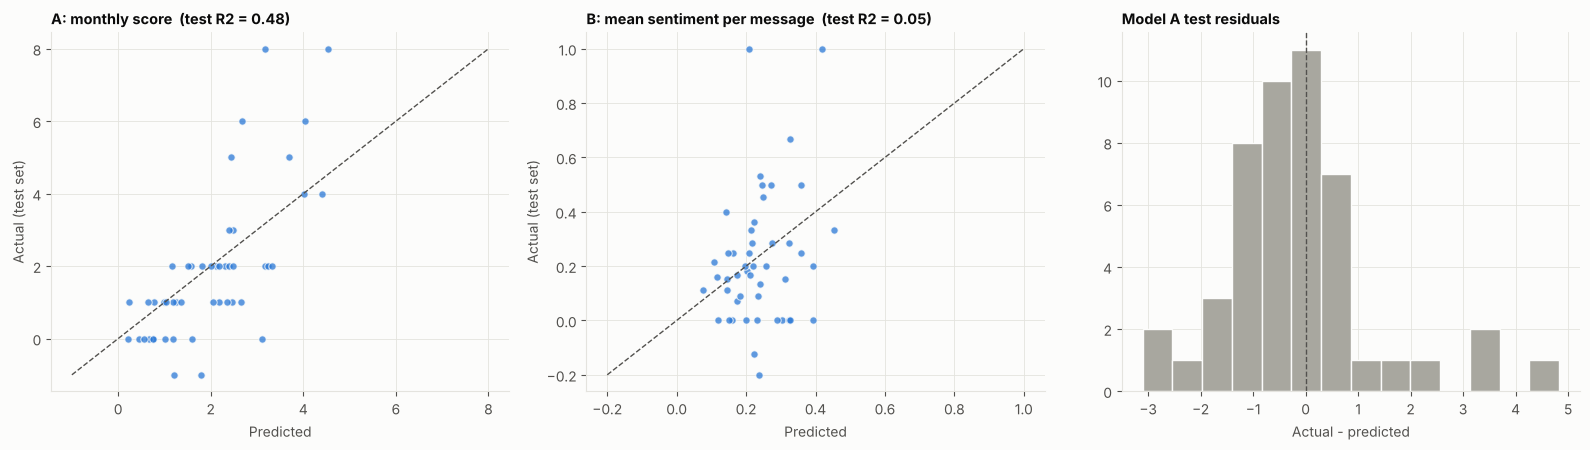

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, res, ttl in ((axes[0], resA, "A: monthly score"), (axes[1], resB, "B: mean sentiment per message")):
    y, p = res["y_test"], res["pred_test"]
    ax.scatter(p, y, s=28, color=C["Positive"], alpha=0.75, edgecolor=C["surface"], linewidth=0.8)
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max())
    ax.plot([lo, hi], [lo, hi], color=C["ink2"], ls="--", lw=1)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual (test set)")
    ax.set_title(f"{ttl}  (test R2 = {res['metrics']['r2_test']:.2f})", fontsize=10.5)
resid = resA["y_test"] - resA["pred_test"]
axes[2].hist(resid, bins=14, color=C["Neutral"], edgecolor=C["surface"]); axes[2].axvline(0, color=C["ink2"], ls="--", lw=1)
axes[2].set_title("Model A test residuals", fontsize=10.5); axes[2].set_xlabel("Actual - predicted")
fig.tight_layout(); save(fig, "09_model_actual_vs_predicted.png")

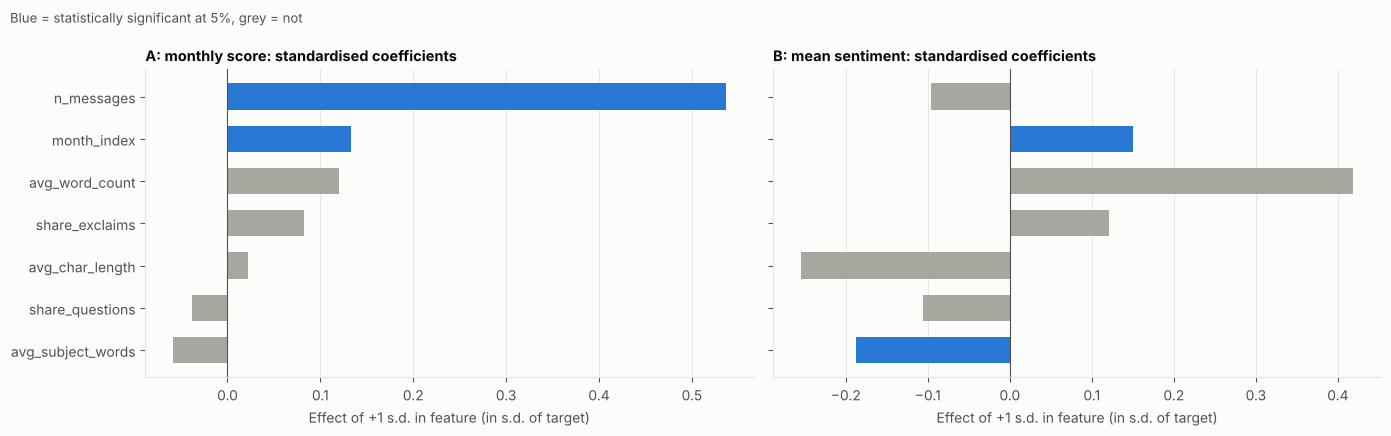

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, res, ttl in ((axes[0], resA, "A: monthly score"), (axes[1], resB, "B: mean sentiment")):
    c = res["coefs"].iloc[1:].set_index("feature")["std_coef"].sort_values()
    sig = res["coefs"].iloc[1:].set_index("feature")["p_value"].reindex(c.index) < 0.05
    ax.barh(c.index, c.values, color=[C["Positive"] if s else C["Neutral"] for s in sig], height=0.62)
    ax.axvline(0, color=C["ink2"], lw=0.8); ax.grid(axis="y", visible=False)
    ax.set_title(f"{ttl}: standardised coefficients", fontsize=10.5); ax.set_xlabel("Effect of +1 s.d. in feature (in s.d. of target)")
fig.suptitle("Blue = statistically significant at 5%, grey = not", x=0.01, ha="left", color=C["ink2"], fontsize=9.5)
fig.tight_layout(); save(fig, "10_model_coefficients.png")

**Observations - what the model does and does not tell us.**
* **Model A (monthly score)** explains a moderate share of variance on unseen data
  (test R-squared about 0.48, test RMSE about 1.48 vs 2.06 for the mean-only baseline; 5-fold CV
  R-squared is lower at ~0.28, so the test figure is partly luck of the split). **`n_messages` is by far the
  strongest coefficient** (~+0.17 score points per extra message, p < 0.001). That is largely
  *arithmetic*: more messages -> a bigger sum. It is a real but unsurprising relationship, not evidence that
  busy people are happier. `month_index` is also significant at the 5% level (p = 0.028, ~+0.035 points per month), echoing the
  slow upward drift in section 2.3.
* **Model B (tone per message)** has **essentially no predictive power**: test R-squared is about 0.05 and CV R-squared is
  negative (-0.11) - it does no better than guessing the average. Two features reach p < 0.05:
  `avg_subject_words` (longer subject lines -> slightly lower sentiment) and `month_index` (the same slow
  upward drift), but with seven features tested and no out-of-sample gain these are weak evidence.
* **Interpretation.** Simple structural features (length, punctuation, frequency) do **not**
  forecast how positive someone's mail will be once volume is controlled for. A better model would
  need content features (topics, recipients, seniority, deal calendar) or genuine time-ordered data.
* **Caveats.** 240 observations, a lexicon-generated target (label noise flows straight into
  the regression), the synthetic-looking dates, and a linear model on bounded, discrete scores.
  Residuals (right-hand panel above) are centred near zero but right-skewed: a handful of very high-score months are under-predicted. The fit is adequate for a baseline, not for forecasting.

## 7. Summary & exports

In [29]:
# ---- export all result tables ----
df_out = df.drop(columns=["word_count"], errors="ignore")
df_out[["employee", "date", "month", "subject", "body", "sentiment_score", "sentiment", "message_score"]] \
    .to_csv(os.path.join(ROOT, "data", "test_labeled.csv"), index=False)
scores.to_csv(os.path.join(OUT, "monthly_scores.csv"), index=False)
top_pos.to_csv(os.path.join(OUT, "monthly_top3_positive.csv"), index=False)
top_neg.to_csv(os.path.join(OUT, "monthly_top3_negative.csv"), index=False)
overall.to_csv(os.path.join(OUT, "overall_ranking.csv"), index=False)
risk.to_csv(os.path.join(OUT, "flight_risks.csv"), index=False)
triggers.to_csv(os.path.join(OUT, "flight_risk_trigger_days.csv"), index=False)
resA["coefs"].assign(model="A: monthly_score").pipe(lambda a: pd.concat([a, resB["coefs"].assign(model="B: mean_sentiment")])) \
    .to_csv(os.path.join(OUT, "model_coefficients.csv"), index=False)
metrics.to_csv(os.path.join(OUT, "model_metrics.csv"))
print("Saved:", sorted(os.listdir(OUT)), "+ data/test_labeled.csv")

# ---- headline results ----
print("\nTOP 3 POSITIVE (total score):", ", ".join(f"{short(e)} ({s})" for e, s in overall.head(3)[["employee", "total_score"]].values))
print("TOP 3 LOWEST   (total score):", ", ".join(f"{short(e)} ({s})" for e, s in overall.tail(3).iloc[::-1][["employee", "total_score"]].values))
print("FLIGHT RISKS:", ", ".join(risk["name"]))

Saved: ['flight_risk_trigger_days.csv', 'flight_risks.csv', 'model_coefficients.csv', 'model_metrics.csv', 'monthly_scores.csv', 'monthly_top3_negative.csv', 'monthly_top3_positive.csv', 'overall_ranking.csv'] + data/test_labeled.csv

TOP 3 POSITIVE (total score): Lydia Delgado (66), Eric Bass (60), John Arnold (59)
TOP 3 LOWEST   (total score): Rhonda Denton (25), Kayne Coulter (37), Patti Thompson (38)
FLIGHT RISKS: Bobette Riner


### Key insights & recommendations
1. **Overall tone is healthy and drifting up** - 30% positive vs 7% negative, with a small upward trend.
   Negative e-mail is rare, so concentrated bursts of negativity stand out.
2. **One employee is flagged** (Bobette Riner): exactly four negatives in 30 days. This is a *marginal*
   flag from a lexicon labeller, and the list changes with the threshold (7 people at +-0.15, none at
   +-0.35) - use it to start a conversation, not to conclude anything. Read the evidence messages first.
3. **Rankings show small differences** - all ten employees have positive totals. Rhonda Denton, Kayne Coulter
   and Patti Thompson score lowest; for Rhonda and Kayne this is partly lower message volume, while Patti sent
   a typical number of messages and has a lower per-message score.
4. **Do not use the regression to forecast sentiment.** Volume explains the *score*; nothing structural
   explains the *tone*.
5. **Before anyone acts on this:** validate labels against human-labelled data (or an LLM) and
   verify the date column - the synthetic-looking dates limit any time-based conclusion.